# Compare Original and Background-Removed Leaf Images
This notebook cell displays a random set of 10 healthy leaf images side by side with their background-removed versions for visual comparison.

Background-removed image not found for healthy_0835.png, skipping.


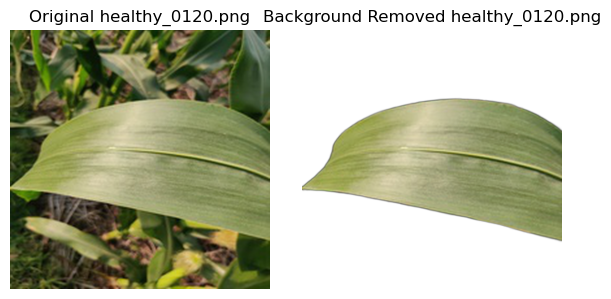

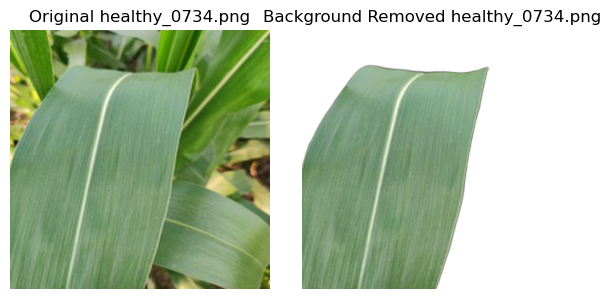

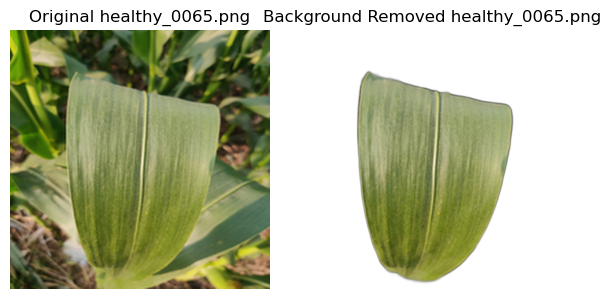

Background-removed image not found for healthy_0231.png, skipping.


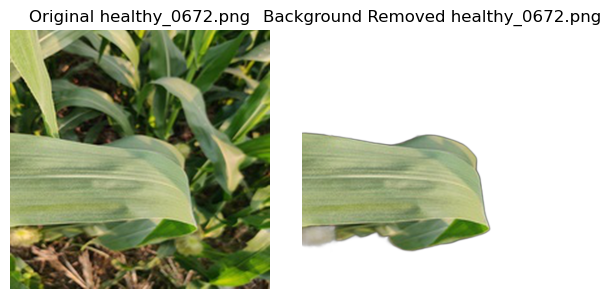

Background-removed image not found for healthy_0867.png, skipping.
Background-removed image not found for healthy_0959.png, skipping.
Background-removed image not found for healthy_0952.png, skipping.
Background-removed image not found for healthy_0327.png, skipping.


In [8]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

# Set your folders
original_folder = r'C:\Users\henry\Desktop\isef2026\data\healthy_500x500'  # e.g., 'data/healthy'
removed_bg_folder = r'C:\Users\henry\Desktop\isef2026\data\healthy_no_background_filtered'  # e.g., 'data/healthy_no_bg'

# List of images to compare
image_files = [f for f in os.listdir(original_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
image_files = random.sample(image_files, min(10, len(image_files)))  # Random 10 images

for fname in image_files:
    orig_path = os.path.join(original_folder, fname)
    base_name = os.path.splitext(fname)[0]
    removed_bg_path = os.path.join(removed_bg_folder, base_name + '.png')
    if not os.path.exists(removed_bg_path):
        print(f'Background-removed image not found for {fname}, skipping.')
        continue
    orig_img = Image.open(orig_path).convert('RGB')
    removed_bg_img = Image.open(removed_bg_path).convert('RGBA')
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    axes[0].imshow(orig_img)
    axes[0].set_title('Original ' + fname)  # Show filename in title
    axes[0].axis('off')
    axes[1].imshow(removed_bg_img)
    axes[1].set_title('Background Removed ' + fname)
    axes[1].axis('off')
    plt.tight_layout()
    plt.show()

Copied 620 images to filtered folder (out of 1038).
Skipped 418 images.


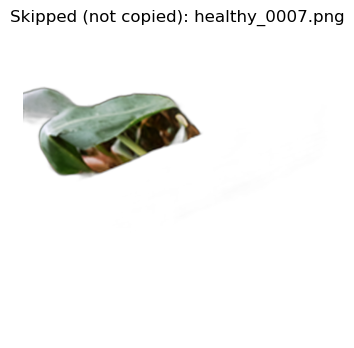

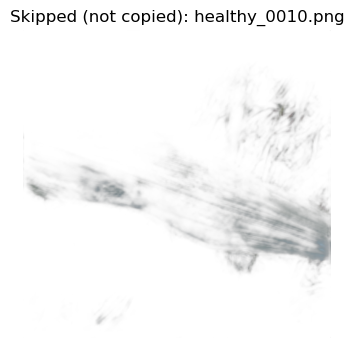

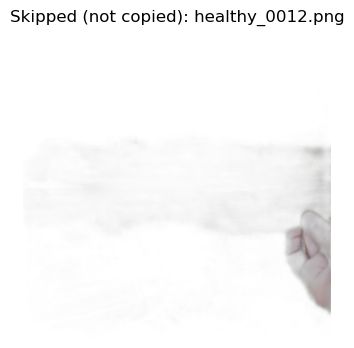

In [9]:
import os
import numpy as np
from PIL import Image
import shutil
import matplotlib.pyplot as plt

input_folder = r'C:\Users\henry\Desktop\isef2026\data\healthy_no_background'
output_folder = r'C:\Users\henry\Desktop\isef2026\data\healthy_no_background_filtered'
os.makedirs(output_folder, exist_ok=True)

min_coverage = 0.15  # Minimum fraction of non-transparent pixels (e.g., 15%)
max_coverage = 0.90  # Maximum fraction (e.g., 90%)

kept = []
skipped = []

for fname in os.listdir(input_folder):
    if not fname.lower().endswith('.png'):
        continue
    img = Image.open(os.path.join(input_folder, fname)).convert('RGBA')
    alpha = np.array(img)[..., 3]
    coverage = np.count_nonzero(alpha > 128) / alpha.size
    if min_coverage <= coverage <= max_coverage:
        kept.append(fname)
        shutil.copy2(os.path.join(input_folder, fname), os.path.join(output_folder, fname))
    else:
        skipped.append(fname)

print(f'Copied {len(kept)} images to filtered folder (out of {len(os.listdir(input_folder))}).')
print(f'Skipped {len(skipped)} images.')

# Show up to 3 skipped examples
for i, fname in enumerate(skipped[:3]):
    img = Image.open(os.path.join(input_folder, fname)).convert('RGBA')
    plt.figure(figsize=(4, 4))
    plt.imshow(img)
    plt.title(f"Skipped (not copied): {fname}")
    plt.axis('off')
    plt.show()

In [5]:
import os
from PIL import Image
import imagehash

folder = r'C:\Users\henry\Desktop\isef2026\data\healthy_no_background_filtered'
hash_map = {}

for fname in os.listdir(folder):
    if not fname.lower().endswith('.png'):
        continue
    img = Image.open(os.path.join(folder, fname)).convert('RGBA')
    # Only hash the RGB channels to focus on leaf content
    img_rgb = img.convert('RGB')
    h = imagehash.phash(img_rgb)
    if h in hash_map:
        print(f"Deleting near-duplicate: {fname} (matches {hash_map[h]})")
        os.remove(os.path.join(folder, fname))
    else:
        hash_map[h] = fname

print("Near-duplicate images deleted.")

Deleting near-duplicate: healthy_0051.png (matches healthy_0050.png)
Deleting near-duplicate: healthy_0057.png (matches healthy_0056.png)
Deleting near-duplicate: healthy_0061.png (matches healthy_0060.png)
Deleting near-duplicate: healthy_0063.png (matches healthy_0062.png)
Deleting near-duplicate: healthy_0067.png (matches healthy_0066.png)
Deleting near-duplicate: healthy_0071.png (matches healthy_0070.png)
Deleting near-duplicate: healthy_0073.png (matches healthy_0072.png)
Deleting near-duplicate: healthy_0075.png (matches healthy_0074.png)
Deleting near-duplicate: healthy_0083.png (matches healthy_0082.png)
Deleting near-duplicate: healthy_0085.png (matches healthy_0084.png)
Deleting near-duplicate: healthy_0091.png (matches healthy_0090.png)
Deleting near-duplicate: healthy_0093.png (matches healthy_0092.png)
Deleting near-duplicate: healthy_0095.png (matches healthy_0094.png)
Deleting near-duplicate: healthy_0097.png (matches healthy_0096.png)
Deleting near-duplicate: healthy_0